In [2]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


## Perspective transformation

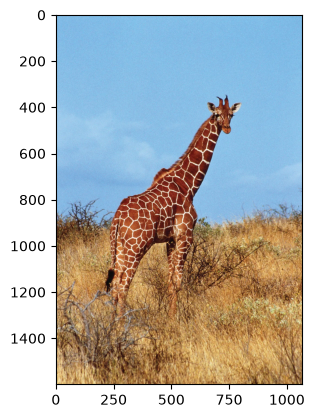

In [6]:
image = cv2.imread("../Images/giraffe-Kenya.png")
image_rgb = cv2.cvtColor(image,cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)

In [7]:
rows, cols, _ = image_rgb.shape


In [8]:
input_points = np.float32([[50,50],[cols-50,50],[50,rows-50],[cols-50,rows-50]])
output_points = np.float32([[10,100],[cols-100,50],[100,rows-10],[cols-50,rows-100]])

'''
Transformation matrix for perspective transformation

3x3

a,b,c
d,e,f
g,h,1

where

a,b,c is responsible for horizontal scaling, rotation and translation
d,e,f is responsible for vertical scaling, rotation and translation
g,h perspective components that accounts for depth and skew

'''

M = cv2.getPerspectiveTransform(input_points,output_points)

print(M)

[[ 1.02287821e+00  6.29847356e-02 -4.42634568e+01]
 [-5.02940991e-02  1.04090741e+00  5.07662367e+01]
 [ 3.13145264e-05  2.80659423e-05  1.00000000e+00]]


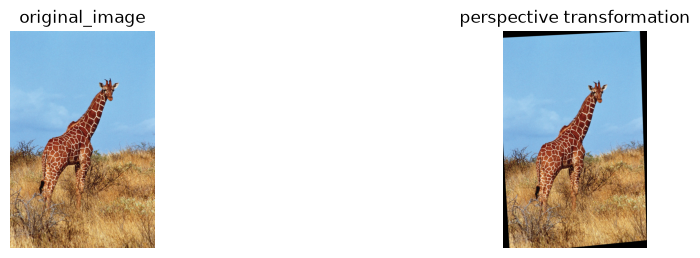

In [12]:
perspective_image = cv2.warpPerspective(image_rgb,M,(cols,rows))


plt.figure(figsize=(10,5))

plt.subplot(2,2,1)
plt.imshow(image_rgb)
plt.title("original_image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(perspective_image)
plt.title("perspective transformation")
plt.axis("off")

plt.tight_layout()
plt.show()


## Affine transformation

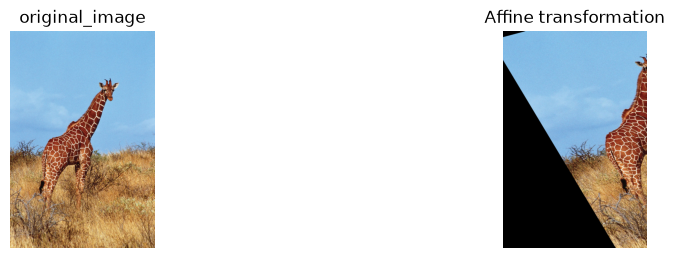

In [13]:
input_points = np.float32([[50,50],[200,50],[50,200]])
output_points = np.float32([[10,100],[200,50],[100,250]])


M = cv2.getAffineTransform(input_points,output_points)

affine_image = cv2.warpAffine(image_rgb,M,(cols,rows))

plt.figure(figsize=(10,5))

plt.subplot(2,2,1)
plt.imshow(image_rgb)
plt.title("original_image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(affine_image)
plt.title("Affine transformation")
plt.axis("off")

plt.tight_layout()
plt.show()



## Rotation

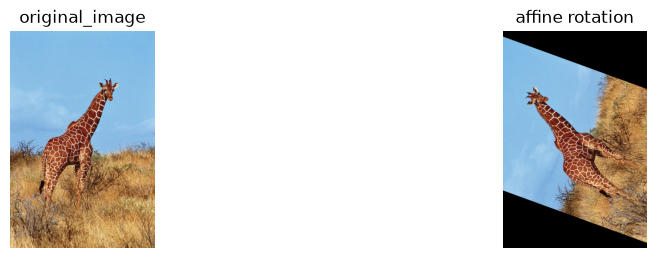

In [16]:
angle = 70
centre =(cols//2,rows//2)
scale = 1.0

M = cv2.getRotationMatrix2D(centre,angle,scale)

rotated_image = cv2.warpAffine(image_rgb,M,(cols,rows))

plt.figure(figsize=(10,5))

plt.subplot(2,2,1)
plt.imshow(image_rgb)
plt.title("original_image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(rotated_image)
plt.title(" affine rotation ")
plt.axis("off")

plt.tight_layout()
plt.show()


## Shearing

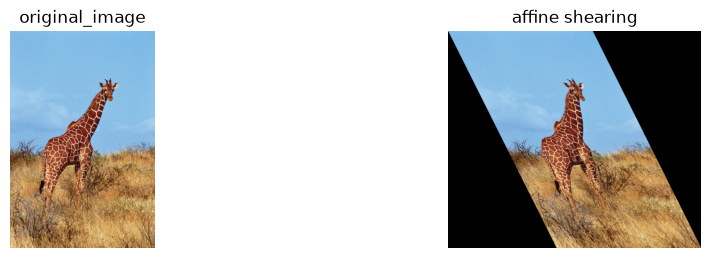

In [18]:

shear_x, shear_y = 0.5,0

M = np.float32([[1,shear_x,0],[shear_y,1,0]])



shear_image = cv2.warpAffine(image_rgb,M,(cols + int(shear_x*rows),rows))

plt.figure(figsize=(10,5))

plt.subplot(2,2,1)
plt.imshow(image_rgb)
plt.title("original_image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(shear_image)
plt.title(" affine shearing ")
plt.axis("off")

plt.tight_layout()
plt.show()

## Translation

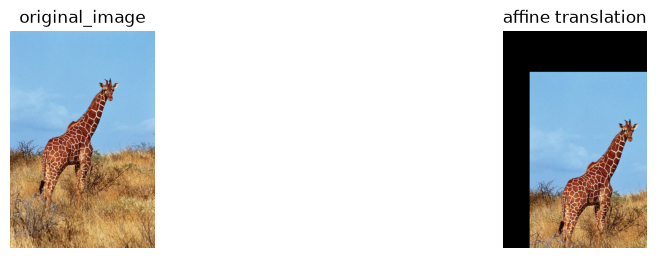

In [19]:

tx, ty = 200,300

M = np.float32([[1,0,tx],[0,1,ty]])



translation_image = cv2.warpAffine(image_rgb,M,(cols ,rows))

plt.figure(figsize=(10,5))

plt.subplot(2,2,1)
plt.imshow(image_rgb)
plt.title("original_image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(translation_image)
plt.title(" affine translation ")
plt.axis("off")

plt.tight_layout()
plt.show()